<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta5_g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: NVIDIA RTX PRO 6000 Blackwell Server Edition


--> Kendi yazdığımız fonksiyon ile OpenCV çıktısı arasındaki toplam hata değeri: 130450


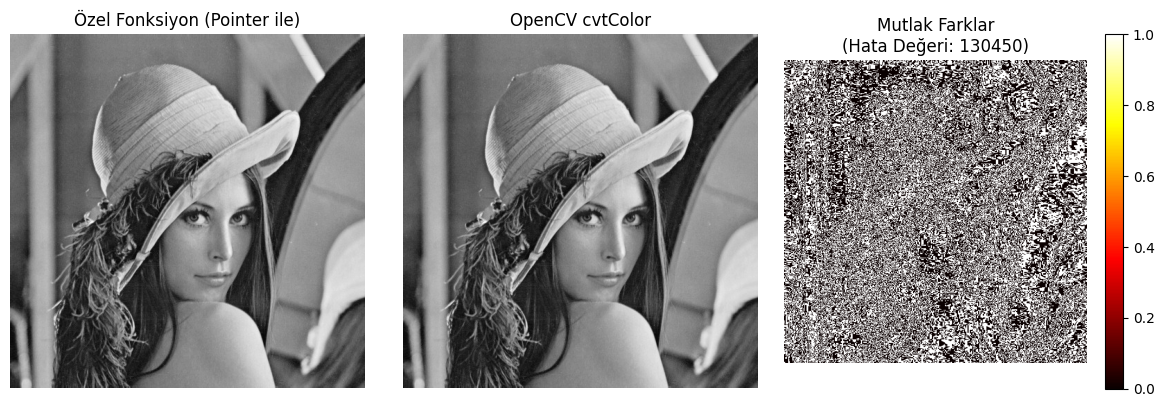

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# 1. Test için örnek renkli bir görüntü indirelim (BGR formatında)
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

# -------------------------------------------------------------
# 2. Renk Uzayı Dönüşüm Fonksiyonları (Alt Fonksiyonlar)
# -------------------------------------------------------------
def bgr_to_gray_custom(image):
    """
    BGR görüntüyü gri tonlamalıya çeviren özel fonksiyonumuz.
    Formül: 0.114*B + 0.587*G + 0.299*R
    """
    b, g, r = cv2.split(image.astype(np.float32))
    gray = 0.114 * b + 0.587 * g + 0.299 * r
    return np.clip(gray, 0, 255).astype(np.uint8)

# C++'daki fonksiyon pointer mantığı:
# C++'ta: void (*func_ptr)(const cv::Mat&, cv::Mat&) = bgr_to_gray_custom;
# Python'da fonksiyonlar birinci sınıf nesne (first-class citizen) olduğu için
# direkt değişkenlere atanabilir ve birer fonksiyon pointerı gibi çalıştırılabilir.
def apply_conversion(image, func_ptr):
    """
    Parametre olarak bir fonksiyon pointerı (referansı) alır
    ve gönderilen resmi o fonksiyona sokarak dönüştürür.
    """
    return func_ptr(image)

# -------------------------------------------------------------
# 3. Fonksiyon Pointerı Kullanarak Dönüşümü Gerçekleştirme
# -------------------------------------------------------------
# Fonksiyonu bir değişkene (pointer gibi) atıyoruz
conversion_pointer = bgr_to_gray_custom

# Fonksiyon pointerı aracılığıyla dönüşüm yapılıyor
my_gray_img = apply_conversion(img, conversion_pointer)

# -------------------------------------------------------------
# 4. OpenCV Hazır Fonksiyonu ile Dönüşüm
# -------------------------------------------------------------
opencv_gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# -------------------------------------------------------------
# 5. Sayısal Kıyaslama ve Hata Değeri Hesaplama
# -------------------------------------------------------------
# İki görüntü arasındaki piksel farklarının mutlak toplamı (SAD)
absolute_diff = np.abs(my_gray_img.astype(np.int32) - opencv_gray_img.astype(np.int32))
total_error = np.sum(absolute_diff)

print(f"--> Kendi yazdığımız fonksiyon ile OpenCV çıktısı arasındaki toplam hata değeri: {total_error}")
if total_error == 0:
    print("Harika! Beklendiği gibi hata değeri sıfır (0) çıktı.")

# -------------------------------------------------------------
# 6. Görselleştirme
# -------------------------------------------------------------
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(my_gray_img, cmap='gray')
plt.title('Özel Fonksiyon (Pointer ile)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(opencv_gray_img, cmap='gray')
plt.title('OpenCV cvtColor')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(absolute_diff, cmap='hot')
plt.title(f'Mutlak Farklar\n(Hata Değeri: {total_error})')
plt.colorbar()
plt.axis('off')

plt.tight_layout()
plt.show()